# Estudo 07 – H6: a volatilidade é previsível? Para que serve?

Hipótese H6 das [notas](../NOTAS.md). Todos os estudos anteriores apontaram na mesma direção:

- a **direção** do próximo retorno é ruído;
- o **tamanho** dos movimentos tem memória: |retorno| autocorrelacionado (relatório original), próximo movimento maior depois de um grande (Estudo 05), volatilidade de ontem prevendo a de hoje (Estudo 06);
- e um **padrão intradiário** forte: a abertura ~3 vezes mais volátil que o fim do dia.

Este estudo mede **quanto** a volatilidade é previsível, em dois níveis, e o que dá para fazer com isso:

1. **Volatilidade diária:** prever a volatilidade de hoje com a dos dias anteriores (modelo **HAR**).
2. **Volatilidade de cada candle de 60 min:** bandas de previsão que acertem **em todos os horários**. É o problema que o SARIMAX da frente deixou em aberto: a banda de 95% cobria só 74% às 10h e 99% às 18h.
3. **Uso:** o que uma boa previsão de volatilidade faz e não faz numa estratégia.

**Dados:** WIN, só até 31/12/2024. Avaliação **fora da amostra**: para prever o ano A, os modelos são estimados só com dados anteriores a A (A = 2022, 2023, 2024).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, sys
from pathlib import Path
from scipy import stats
from scipy.optimize import minimize

PASTA = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "tt1_comum.py").exists())
sys.path.append(str(PASTA))
import tt1_comum as t

AZUL, LARANJA, VERDE, CINZA, VIOLETA = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984", "#6250d6"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
                     "axes.edgecolor": "#a3a29c", "axes.labelcolor": "#52514e",
                     "xtick.color": "#52514e", "ytick.color": "#52514e", "lines.linewidth": 1.6})
ANOS_TESTE = [2022, 2023, 2024]

win = t.carregar(f"{PASTA}/dados/WINN_M1/WIN$N_M1.csv")
win = win[win.index < "2025-01-01"]

# retornos de 1 min dentro do pregão → variância realizada de cada dia (pregões completos)
d1 = pd.Series(win.index.normalize(), index=win.index)
r1 = np.log(win.close).diff(); r1[d1 != d1.shift()] = np.nan
n_min = r1.groupby(d1).count()
rv = (r1 ** 2).groupby(d1).sum() * 1e4                 # variância realizada do dia, em %²
rv = rv[n_min >= 400]
ret_dia = (np.log(win.close).groupby(d1).last() - np.log(win.open).groupby(d1).first()).reindex(rv.index) * 100
print(f"{len(rv)} pregões completos")

928 pregões completos


## 1. Direção × tamanho: a diferença em um gráfico

Autocorrelação do **retorno do dia** (direção) e da **volatilidade realizada do dia** (tamanho), em defasagens de 1 dia a 3 meses.

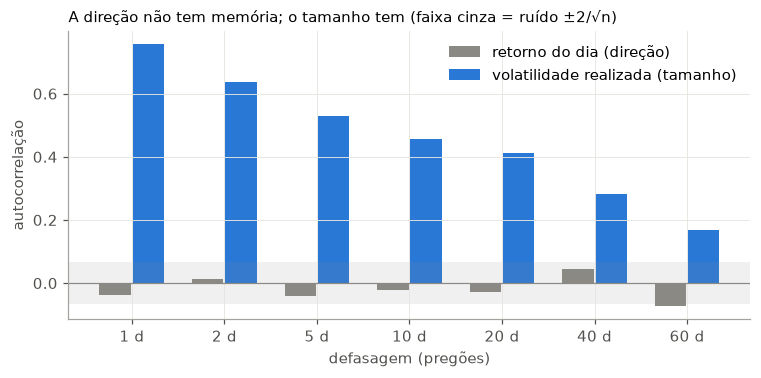

autocorrelação da volatilidade: {1: np.float64(0.76), 2: np.float64(0.64), 5: np.float64(0.53), 10: np.float64(0.46), 20: np.float64(0.41), 40: np.float64(0.28), 60: np.float64(0.17)}


In [2]:
lags = [1, 2, 5, 10, 20, 40, 60]
ac_ret = [ret_dia.autocorr(k) for k in lags]
ac_vol = [np.sqrt(rv).autocorr(k) for k in lags]
faixa = 2 / np.sqrt(len(rv))

fig, ax = plt.subplots(figsize=(8, 3.4))
xs = np.arange(len(lags))
ax.bar(xs - 0.18, ac_ret, width=0.34, color=CINZA, label="retorno do dia (direção)")
ax.bar(xs + 0.18, ac_vol, width=0.34, color=AZUL, label="volatilidade realizada (tamanho)")
ax.axhspan(-faixa, faixa, color=CINZA, alpha=0.12, lw=0); ax.axhline(0, color=CINZA, lw=0.8)
ax.set_xticks(xs, [f"{k} d" for k in lags]); ax.set_xlabel("defasagem (pregões)"); ax.set_ylabel("autocorrelação")
ax.legend(frameon=False); ax.set_title("A direção não tem memória; o tamanho tem (faixa cinza = ruído ±2/√n)", loc="left", fontsize=10)
plt.show()
print("autocorrelação da volatilidade:", dict(zip(lags, np.round(ac_vol, 2))))

**Leitura:** o retorno do dia fica dentro da faixa de ruído em todas as defasagens. A volatilidade tem autocorrelação de **0,76 com o dia anterior** e ainda ~0,4 um mês depois. É o contraste do trabalho inteiro em um gráfico.

## 2. Prevendo a volatilidade do dia: o modelo HAR

O **HAR** (*Heterogeneous AutoRegressive*, Corsi 2009) é o modelo mais usado na literatura para volatilidade realizada. A ideia: participantes com horizontes diferentes (operadores de dia, de semana, de mês) reagem à volatilidade na sua própria escala. Então a de amanhã depende de três médias:

$$\ln RV_{d} = b_0 + b_1 \ln RV_{d-1} + b_2 \ln \overline{RV}_{\,5\ dias} + b_3 \ln \overline{RV}_{\,22\ dias} + \varepsilon_d$$

É só uma regressão linear (em log, porque a volatilidade é sempre positiva e assimétrica).

**Como medir o acerto de uma previsão de volatilidade:**

- **R² contra a média histórica:** quanto da variação da volatilidade a previsão explica, comparada a prever sempre a média.
- **QLIKE** = média de ln(previsão) + realizado/previsão. É a perda padrão para volatilidade: pune mais **subestimar** (o que dói em gestão de risco) do que superestimar. Menor é melhor.

Referências simples: média histórica, a volatilidade de ontem, a média dos últimos 22 dias.

In [3]:
X = pd.DataFrame({"d": rv.shift(1), "w": rv.shift(1).rolling(5).mean(), "m": rv.shift(1).rolling(22).mean(), "y": rv}).dropna()

def har_ajusta(tr):
    A = np.c_[np.ones(len(tr)), np.log(tr[["d", "w", "m"]])]
    b, *_ = np.linalg.lstsq(A, np.log(tr.y), rcond=None)
    return b, np.var(np.log(tr.y) - A @ b)

def har_prevê(b, s2, x):
    return np.exp(np.c_[np.ones(len(x)), np.log(x[["d", "w", "m"]])] @ b + s2 / 2)   # + s2/2: correção do log

linhas, prev_2024 = [], None
for ano in ANOS_TESTE:
    tr, te = X[X.index.year < ano], X[X.index.year == ano]
    b, s2 = har_ajusta(tr)
    previsoes = {"média histórica": np.full(len(te), tr.y.mean()), "ontem": te.d.values,
                 "média de 22 dias": te.m.values, "HAR": har_prevê(b, s2, te)}
    for nome, f in previsoes.items():
        linhas.append(dict(ano=ano, modelo=nome, QLIKE=np.mean(np.log(f) + te.y / f),
                           R2_vs_media=1 - np.sum((te.y - f) ** 2) / np.sum((te.y - previsoes["média histórica"]) ** 2)))
    if ano == 2024:
        prev_2024 = pd.DataFrame({"realizado": te.y, "HAR": previsoes["HAR"], "média histórica": previsoes["média histórica"]})
tab2 = pd.DataFrame(linhas)
print("coeficientes do HAR (ajuste para 2024): b0, ontem, semana, mês =", np.round(b, 2))
tab2.pivot(index="modelo", columns="ano", values=["R2_vs_media", "QLIKE"]).round(3)

coeficientes do HAR (ajuste para 2024): b0, ontem, semana, mês = [-0.01  0.55  0.16  0.19]


R2_vs_media                QLIKE              
ano                     2022   2023   2024   2022   2023   2024
modelo                                                         
HAR                    0.465  0.524  0.901  1.443  1.149  0.476
média de 22 dias       0.221  0.488  0.895  1.483  1.155  0.496
média histórica        0.000  0.000  0.000  1.522  1.238  0.804
ontem                  0.314  0.378  0.867  1.465  1.168  0.498

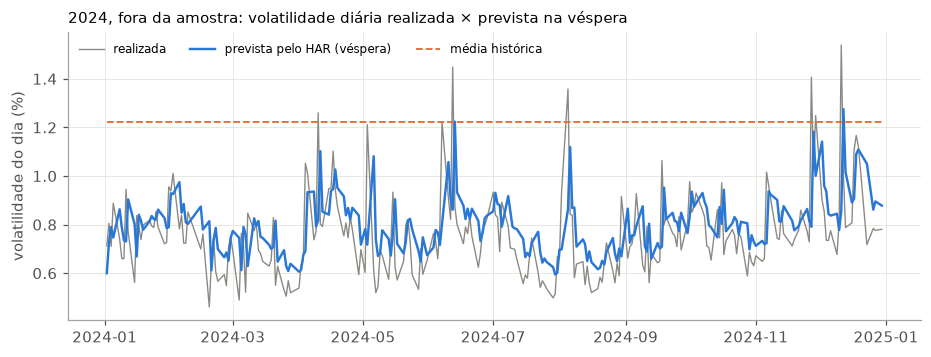

In [4]:
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(prev_2024.index, np.sqrt(prev_2024.realizado), color=CINZA, lw=0.9, label="realizada")
ax.plot(prev_2024.index, np.sqrt(prev_2024.HAR), color=AZUL, lw=1.6, label="prevista pelo HAR (véspera)")
ax.plot(prev_2024.index, np.sqrt(prev_2024["média histórica"]), color=LARANJA, lw=1.2, ls="--", label="média histórica")
ax.set_ylabel("volatilidade do dia (%)"); ax.legend(frameon=False, ncol=3, fontsize=8)
ax.set_title("2024, fora da amostra: volatilidade diária realizada × prevista na véspera", loc="left", fontsize=10); plt.show()

**Leitura:**

- O HAR explica de **47% a 90%** da variação da volatilidade diária fora da amostra, conforme o ano, e é o melhor em todos os anos e nas duas métricas. Só "a volatilidade de ontem" já explica 31–87%.
- Compare com a direção: o R² fora da amostra do retorno ficou em ≈ 0,0002 (Estudo 01) e negativo nos modelos da frente.
- Os pesos (ontem ≈ 0,55; semana ≈ 0,16; mês ≈ 0,19) mostram que a memória tem várias escalas: o dia anterior pesa mais, mas a semana e o mês também contam.
- Em 2024 a média histórica erra feio porque o nível de volatilidade caiu (de ~20% para ~12% ao ano). O HAR acompanha a mudança.

## 3. Bandas de previsão para cada candle de 60 min

Agora o problema da frente: uma banda de 95% para o retorno de cada candle de 60 min que cubra 95% **em todos os horários**. Cinco modelos para a variância σ² do próximo candle, todos usando só informação disponível antes dele:

| Modelo | σ² do candle | Comentário |
|---|---|---|
| **constante** | variância média do treino | o que o SARIMAX assume |
| **volat do simulador** | variância dos últimos 10 candles (~1 pregão) | é o `volat` que define TP e SL no `tt1_comum.simular` |
| **perfil** | variância média **daquela hora** no treino | captura o padrão intradiário |
| **perfil × nível do dia** | perfil(hora) × (HAR do dia ÷ média) | padrão intradiário + volatilidade do dia prevista na véspera |
| **GARCH no perfil** | perfil(hora) × GARCH(1,1) do retorno dividido pelo perfil | padrão intradiário + choques recentes, candle a candle |

**O GARCH(1,1)** (Bollerslev, 1986) atualiza a variância a cada candle:

$$\sigma^2_t = \omega + \alpha\, u^2_{t-1} + \beta\, \sigma^2_{t-1}$$

Um choque grande no candle anterior (u²) aumenta a variância prevista (peso α), e a variância anterior persiste (peso β). Implementado abaixo em poucas linhas, estimando ω, α, β por máxima verossimilhança. Os parâmetros são estimados no treino e ficam fixos no ano de teste, como no `extend` do ARIMA da frente.

Banda de 95%: ±1,96·σ (supõe normal). **Cobertura** = fração dos candles cujo retorno caiu dentro da banda.

In [5]:
c = win.resample("60min").agg({"open": "first", "close": "last"}).dropna()
d = pd.Series(c.index.normalize(), index=c.index); novo = d != d.shift()
r = np.log(c.close).diff() * 100; r[novo] = np.log(c.close / c.open)[novo] * 100   # 1º candle: abertura → fechamento (como no montar_base)
H = pd.DataFrame({"r": r, "hora": c.index.hour, "dia": d}).dropna()

def garch_nll(p, u, v0):
    om, a, b = p
    if a + b >= 0.999:
        return 1e10
    s2 = np.empty(len(u)); s2[0] = v0
    for i in range(1, len(u)):
        s2[i] = om + a * u[i - 1] ** 2 + b * s2[i - 1]
    return np.sum(np.log(s2) + u ** 2 / s2)                  # −2 × log-verossimilhança normal (sem constantes)

def garch_filtra(u, p, v0):
    om, a, b = p; s2 = np.empty(len(u)); s2[0] = v0
    for i in range(1, len(u)):
        s2[i] = om + a * u[i - 1] ** 2 + b * s2[i - 1]
    return s2

MODELOS = ["constante", "volat do simulador", "perfil", "perfil × nível", "GARCH no perfil"]
testes, parametros = [], {}
for ano in ANOS_TESTE:
    tr, te = H[H.dia.dt.year < ano].copy(), H[H.dia.dt.year == ano].copy()
    perfil = (tr.r ** 2).groupby(tr.hora).mean()
    b, s2r = har_ajusta(X[X.index.year < ano])
    nivel = pd.Series(har_prevê(b, s2r, X[X.index.year == ano]), index=X[X.index.year == ano].index) / X[X.index.year < ano].y.mean()
    tudo = pd.concat([tr, te]); ntr = len(tr)
    u = (tudo.r / np.sqrt(tudo.hora.map(perfil))).values
    v0 = np.var(u[:ntr])
    p = minimize(garch_nll, [v0 * 0.05, 0.05, 0.9], args=(u[:ntr], v0), bounds=[(1e-8, None), (0, 1), (0, 1)], method="L-BFGS-B").x
    parametros[ano] = p
    te["constante"] = (tr.r ** 2).mean()
    te["volat do simulador"] = (tudo.r.rolling(10, min_periods=5).std().shift(1) ** 2).values[ntr:]
    te["perfil"] = te.hora.map(perfil)
    te["perfil × nível"] = te.perfil * te.dia.map(nivel)
    te["GARCH no perfil"] = garch_filtra(u, p, v0)[ntr:] * te.hora.map(perfil).values
    te["ano"] = ano
    testes.append(te)
T = pd.concat(testes).dropna()
print("GARCH (ω, α, β) por ano de teste:", {a: np.round(v, 3) for a, v in parametros.items()})

linhas = []
for ano in ANOS_TESTE + ["2022–24"]:
    x = T if ano == "2022–24" else T[T.ano == ano]
    for m in MODELOS:
        cob = x.r.abs() <= 1.96 * np.sqrt(x[m])
        linhas.append(dict(ano=ano, modelo=m, QLIKE=np.mean(np.log(x[m]) + x.r ** 2 / x[m]), cobertura=cob.mean(),
                           cobertura_10h=cob[x.hora == 10].mean(), cobertura_18h=cob[x.hora == 18].mean()))
tab3 = pd.DataFrame(linhas)
tab3[tab3.ano == "2022–24"].round(3)

GARCH (ω, α, β) por ano de teste: {2022: array([0.014, 0.057, 0.929]), 2023: array([0.012, 0.041, 0.947]), 2024: array([0.009, 0.036, 0.955])}


,ano,modelo,QLIKE,cobertura,cobertura_10h,cobertura_18h
15,2022–24,constante,-1.088,0.961,0.893,0.995
16,2022–24,volat do simulador,-1.018,0.908,0.765,0.988
17,2022–24,perfil,-1.215,0.964,0.958,0.986
18,2022–24,perfil × nível,-1.410,0.953,0.938,0.979
19,2022–24,GARCH no perfil,-1.405,0.951,0.935,0.979


**Teste de Kupiec:** a cobertura de cada hora é compatível com 95%? Se a banda está certa, cada candle tem 5% de chance de cair fora, e o número de "furos" segue uma binomial. O teste compara o número observado de furos com o esperado. p < 0,05 → a banda daquela hora está **errada** (estreita ou larga demais).

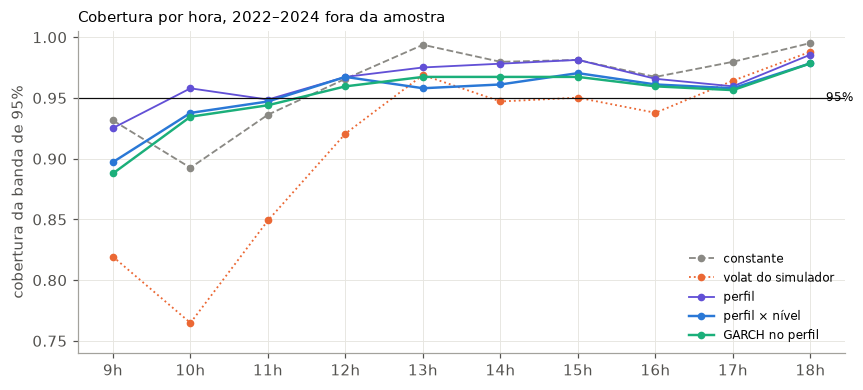

horas com cobertura incompatível com 95% (Kupiec, p < 0,05), de 10:
{'constante': 8, 'volat do simulador': 6, 'perfil': 6, 'perfil × nível': 4, 'GARCH no perfil': 5}


modelo,constante,volat do simulador,perfil,perfil × nível,GARCH no perfil
hora,,,,,
9,0.931,0.819,0.925,0.897,0.888
10,0.893,0.765,0.958,0.938,0.935
11,0.936,0.849,0.949,0.947,0.944
12,0.966,0.921,0.967,0.967,0.960
13,0.994,0.969,0.975,0.958,0.967
14,0.980,0.947,0.978,0.961,0.967
15,0.981,0.950,0.981,0.970,0.967
16,0.967,0.938,0.966,0.961,0.960
17,0.980,0.964,0.960,0.958,0.956


In [6]:
def kupiec(furos, n, p=0.05):
    ph = furos / n
    ll1 = 0.0 if furos in (0, n) else furos * np.log(ph) + (n - furos) * np.log(1 - ph)
    ll0 = furos * np.log(p) + (n - furos) * np.log(1 - p)
    return 1 - stats.chi2.cdf(-2 * (ll0 - ll1), 1)

linhas = []
for m in MODELOS:
    fora = T.r.abs() > 1.96 * np.sqrt(T[m])
    for h, g in fora.groupby(T.hora):
        linhas.append(dict(modelo=m, hora=h, cobertura=1 - g.mean(), p_kupiec=kupiec(g.sum(), len(g))))
K = pd.DataFrame(linhas)

fig, ax = plt.subplots(figsize=(9, 3.8))
estilos = {"constante": (CINZA, "--"), "volat do simulador": (LARANJA, ":"), "perfil": (VIOLETA, "-"),
           "perfil × nível": (AZUL, "-"), "GARCH no perfil": (VERDE, "-")}
for m in MODELOS:
    k = K[K.modelo == m]; cor, ls = estilos[m]
    ax.plot(k.hora, k.cobertura, ls=ls, color=cor, marker="o", ms=4, label=m, lw=1.6 if m in ("perfil × nível", "GARCH no perfil") else 1.2)
ax.axhline(0.95, color="#0b0b0b", lw=0.8); ax.text(18.2, 0.95, "95%", va="center", fontsize=8)
ax.set_xticks(range(9, 19), [f"{h}h" for h in range(9, 19)]); ax.set_ylabel("cobertura da banda de 95%")
ax.legend(frameon=False, fontsize=8, loc="lower right"); ax.set_ylim(0.74, 1.005)
ax.set_title("Cobertura por hora, 2022–2024 fora da amostra", loc="left", fontsize=10); plt.show()

print("horas com cobertura incompatível com 95% (Kupiec, p < 0,05), de 10:")
print(K.assign(rejeita=K.p_kupiec < 0.05).groupby("modelo").rejeita.sum().reindex(MODELOS).to_dict())
K.pivot(index="hora", columns="modelo", values="cobertura")[MODELOS].round(3)

**Leitura:**

- **Constante (como o SARIMAX):** reproduz o problema da frente: 89% às 10h e 97–99,5% à tarde. Erra em 8 das 10 horas.
- **`volat` do simulador: o pior.** 77% às 10h e 82% às 9h. A média do último pregão mistura manhã e tarde e chega atrasada. Como é ela que define a distância do TP e do SL no `tt1_comum.simular`, **os stops da manhã ficam apertados demais e os da tarde, largos demais**.
- **Perfil × nível do dia e GARCH no perfil: os melhores** (menor QLIKE, cobertura perto de 95% na maioria das horas). A cobertura das 10h passa de 74% (SARIMAX da frente) para ~94%.
- **O que sobra:** o candle das 9h ainda fica em ~89–90%. O tamanho do gap quase não ajuda a prever o tamanho da 1ª hora (correlação 0,07; o |retorno| médio da 1ª hora vai só de 0,29% para 0,33% entre gaps pequenos e grandes). A Seção 3.1 investiga.

### 3.1 O que falha na abertura?

**Primeira suspeita: caudas gordas.** Se a abertura tivesse caudas mais gordas, o ±1,96σ da normal seria estreito demais ali. Teste: o quantil de 95% de |retorno ÷ σ| **no treino**, hora a hora. Se fosse isso, o da abertura sairia bem acima de 1,96.

In [7]:
Xtr = X[X.index.year < 2024]; b, s2r = har_ajusta(Xtr)
tr = H[H.dia.dt.year < 2024].copy(); perfil = (tr.r ** 2).groupby(tr.hora).mean()
nivel_tr = pd.Series(har_prevê(b, s2r, Xtr), index=Xtr.index) / Xtr.y.mean()
tr["sig"] = np.sqrt(tr.hora.map(perfil) * tr.dia.map(nivel_tr))
print("quantil de 95% de |r ÷ σ| no treino (até 2023), por hora:",
      (tr.r.abs() / tr.sig).groupby(tr.hora).quantile(0.95).round(2).to_dict())

quantil de 95% de |r ÷ σ| no treino (até 2023), por hora: {9: 2.0, 10: 1.98, 11: 1.98, 12: 2.05, 13: 2.01, 14: 2.17, 15: 2.06, 16: 2.09, 17: 2.03, 18: 1.63}


O multiplicador da abertura sai ≈ 2,0, praticamente o da normal. **Não são as caudas.**

**Segunda suspeita: o padrão intradiário mudou.** Variância de cada hora dividida pela média do dia, ano a ano:

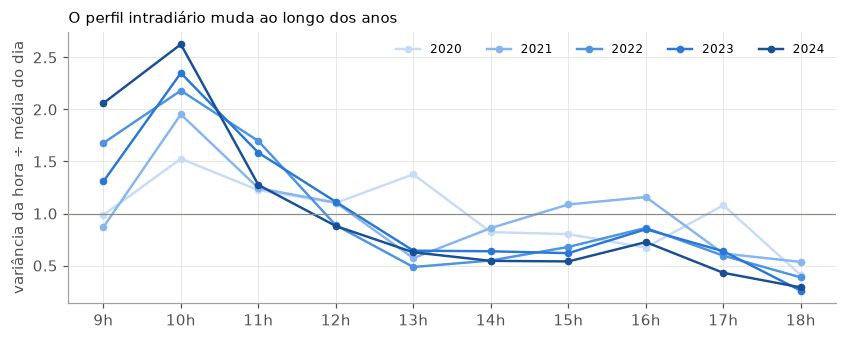

hora,9,10,11,12,13,14,15,16,17,18
ano,,,,,,,,,,
2020,0.99,1.53,1.22,1.10,1.38,0.82,0.80,0.67,1.08,0.41
2021,0.87,1.95,1.24,1.10,0.57,0.86,1.09,1.16,0.62,0.54
2022,1.68,2.18,1.70,0.89,0.49,0.55,0.68,0.86,0.60,0.39
2023,1.31,2.35,1.58,1.11,0.64,0.64,0.62,0.85,0.64,0.26
2024,2.06,2.63,1.27,0.88,0.63,0.55,0.54,0.73,0.43,0.29


In [8]:
rel = (H.r ** 2).groupby([H.dia.dt.year, H.hora]).mean().unstack()
rel = rel.div(rel.mean(axis=1), axis=0)
rel.index.name, rel.columns.name = "ano", "hora"
fig, ax = plt.subplots(figsize=(9, 3.2))
for ano, cor in zip(rel.index, ["#c6dcf7", "#86b6ef", "#4d94e3", "#2a78d6", "#184f95"]):
    ax.plot(rel.columns, rel.loc[ano], marker="o", ms=4, color=cor, label=str(ano))
ax.axhline(1, color=CINZA, lw=0.8)
ax.set_xticks(range(9, 19), [f"{h}h" for h in range(9, 19)]); ax.set_ylabel("variância da hora ÷ média do dia")
ax.legend(frameon=False, fontsize=8, ncol=5); ax.set_title("O perfil intradiário muda ao longo dos anos", loc="left", fontsize=10); plt.show()
rel.round(2)

**É isso:** a hora das 9h foi de ~0,9–1,0 vez a média do dia (2020–21) para **1,7–2,1 vezes** (2022–24). A abertura ficou relativamente muito mais agitada. Um perfil estimado com **todo** o passado mistura o padrão antigo e subestima a abertura recente.

**Correção:** estimar o perfil só com os **últimos 12 meses** antes do ano de teste.

In [9]:
for ano in ANOS_TESTE:
    tr12 = H[(H.dia >= pd.Timestamp(ano - 1, 1, 1)) & (H.dia < pd.Timestamp(ano, 1, 1))]
    perfil12 = (tr12.r ** 2).groupby(tr12.hora).mean()
    escala = (H[H.dia.dt.year < ano].r ** 2).mean() / (tr12.r ** 2).mean()   # mantém o nível médio do perfil completo (o HAR cuida do nível)
    m = T.ano == ano
    T.loc[m, "perfil 12m × nível"] = T.loc[m, "hora"].map(perfil12 * escala).values * (T.loc[m, "perfil × nível"] / T.loc[m, "perfil"]).values

linhas = []
for m_ in ["perfil × nível", "perfil 12m × nível"]:
    fora = T.r.abs() > 1.96 * np.sqrt(T[m_])
    for h, g in fora.groupby(T.hora):
        linhas.append(dict(modelo=m_, hora=h, cobertura=1 - g.mean(), p_kupiec=kupiec(g.sum(), len(g))))
K2 = pd.DataFrame(linhas)
for m_ in ["perfil × nível", "perfil 12m × nível"]:
    k = K2[K2.modelo == m_]
    print(f"{m_:20s} QLIKE = {np.mean(np.log(T[m_]) + T.r ** 2 / T[m_]):.3f} · horas incompatíveis com 95%: "
          f"{int((k.p_kupiec < 0.05).sum())} de 10 · cobertura 9h = {k.set_index('hora').cobertura[9]:.3f} · 10h = {k.set_index('hora').cobertura[10]:.3f}")
K2.pivot(index="hora", columns="modelo", values="cobertura").round(3)

perfil × nível       QLIKE = -1.410 · horas incompatíveis com 95%: 4 de 10 · cobertura 9h = 0.897 · 10h = 0.938
perfil 12m × nível   QLIKE = -1.419 · horas incompatíveis com 95%: 1 de 10 · cobertura 9h = 0.902 · 10h = 0.944


modelo,perfil 12m × nível,perfil × nível
hora,,
9,0.902,0.897
10,0.944,0.938
11,0.956,0.947
12,0.964,0.967
13,0.950,0.958
14,0.953,0.961
15,0.966,0.970
16,0.961,0.961
17,0.955,0.958


**Leitura:** com o perfil dos últimos 12 meses, as horas com cobertura incompatível com 95% caem **de 4 para 1**. Só a hora das 9h continua em ~90%. Ela ficou mais agitada **a cada ano** (1,31 → 2,06 vezes a média entre 2023 e 2024), e mesmo o perfil dos 12 meses anteriores chega atrasado.

**Lição:** um padrão "estável" também precisa ser verificado ao longo do tempo. A estrutura intradiária do WIN mudou bastante em poucos anos. Re-estimar o perfil com mais frequência (por exemplo, a cada trimestre, como no protocolo da frente) é o próximo passo natural.

## 4. Para que serve prever a volatilidade?

**O que ela não faz:** gerar lucro sozinha. Saber que o próximo candle vai mexer ±500 pts não diz se é para comprar ou vender (Estudos 01–05).

**O que ela faz:**

1. **Bandas e stops calibrados.** O TP e o SL do simulador comum são múltiplos do `volat`, o pior modelo da Seção 3. Um stop de "1× a volatilidade" às 10h fica, na prática, bem mais apertado que às 15h, e é acionado por ruído com muito mais frequência. Trocar o `volat` por "perfil × nível" daria a mesma distância **em probabilidade** em qualquer horário.
2. **Risco igual por operação (tamanho da posição).** Dividindo o resultado de cada candle pelo σ previsto, uma previsão boa deixa todas as operações com o **mesmo risco**, seja qual for o horário ou o dia. Isso reduz a dispersão do resultado (e o drawdown) para o mesmo ganho esperado. O teste: o desvio-padrão de r ÷ σ deveria ser ~1 em todas as horas.

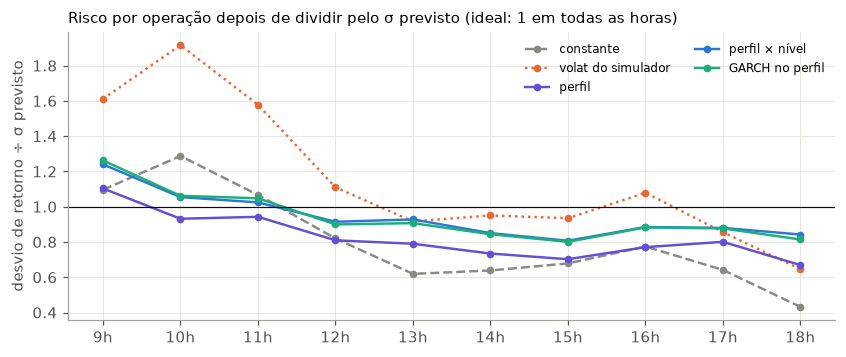

amplitude entre a hora mais arriscada e a menos arriscada (máx ÷ mín): {'constante': 2.98, 'volat do simulador': 2.97, 'perfil': 1.65, 'perfil × nível': 1.54, 'GARCH no perfil': 1.58}


In [10]:
linhas = []
for m in MODELOS:
    padron = (T.r / np.sqrt(T[m])).groupby(T.hora).std()
    linhas.append(padron.rename(m))
P = pd.concat(linhas, axis=1)[MODELOS]

fig, ax = plt.subplots(figsize=(9, 3.4))
for m in MODELOS:
    cor, ls = estilos[m]
    ax.plot(P.index, P[m], ls=ls, color=cor, marker="o", ms=4, label=m)
ax.axhline(1, color="#0b0b0b", lw=0.8)
ax.set_xticks(range(9, 19), [f"{h}h" for h in range(9, 19)]); ax.set_ylabel("desvio de retorno ÷ σ previsto")
ax.legend(frameon=False, fontsize=8, ncol=2)
ax.set_title("Risco por operação depois de dividir pelo σ previsto (ideal: 1 em todas as horas)", loc="left", fontsize=10); plt.show()
print("amplitude entre a hora mais arriscada e a menos arriscada (máx ÷ mín):", (P.max() / P.min()).round(2).to_dict())

**Leitura:** com σ constante (ou com o `volat`), a hora mais arriscada carrega ~3 vezes o risco da menos arriscada: a mesma posição de 1 contrato arrisca muito mais às 9–10h. Com "perfil × nível" ou GARCH, essa razão cai para ~1,5. É isso que permite dimensionar posições e stops de forma coerente.

## 5. Conclusões de H6

| Pergunta | Resposta |
|---|---|
| A volatilidade diária é previsível? | **Muito.** Autocorrelação de 0,76 com o dia anterior. O HAR explica **47–90%** da variação fora da amostra (contra ≈ 0,02% para a direção) |
| Dá para ter bandas certas em todos os horários? | **Quase.** Perfil intradiário × nível do dia (HAR), ou GARCH sobre o perfil, levam a cobertura das 10h de 74% (SARIMAX) para ~94%. Com o perfil dos **últimos 12 meses**, só 1 de 10 horas fica fora de 95%: a abertura, que ficou mais agitada a cada ano (o padrão intradiário mudou entre 2020 e 2024) |
| O `volat` do simulador é bom? | **Não, é o pior modelo:** 77% de cobertura às 10h. TP e SL do simulador comum ficam apertados de manhã e largos à tarde |
| Para que serve? | Não para dar lucro sozinha. Serve para **stops e bandas calibrados** e **risco igual por operação** |

**De volta à frente estatística:** o relatório original concluiu que "a informação útil do SARIMAX é a banda, que precisa variar com o horário". Este estudo faz isso e mede: com perfil intradiário e nível do dia, a banda deixa de errar por horário.

**Propostas que saem daqui** (nas [notas](../NOTAS.md)):

1. Trocar o `volat` do simulador por "perfil × nível" para TP/SL. Junto com a proposta de custos, é uma mudança no simulador comum e precisa do grupo.
2. Usar a volatilidade prevista para **dimensionar** as operações dos candidatos (risco igual por operação). Isso é uma **variante** dos candidatos, e não pode substituir as regras pré-registradas: teria de ser avaliada como hipótese separada.
3. Para a pergunta do projeto ("a melhor abordagem para ganhos reais com T+1"): a previsão T+1 que funciona é a do **tamanho** do próximo candle, e ela melhora a gestão de risco de qualquer estratégia direcional.